# Chapitre 2 - Cours 1 : modèle relationnel contre modèle document

Un modèle de données n'est pas un détail d'implémentation : il décide de ce qui sera
facile ou pénible à écrire, et même de la façon dont on pense le problème. Ce premier
cours ouvre le chapitre 2 par la question la plus débattue de ces dernières années :
ranger ses données en **tables** (modèle relationnel) ou en **documents JSON** (modèle
document) ? Il couvre l'introduction du chapitre et la section *Relational Model Versus
Document Model* : *The Birth of NoSQL*, *The Object-Relational Mismatch*, et la
sous-section *Data locality for queries*.

**Plan.**

1. Des modèles empilés en couches.
2. Un demi-siècle de modèles concurrents, et la naissance de NoSQL.
3. Le décalage objet-relationnel : un CV en objets, en tables, en document.
4. Recomposer un CV : plusieurs requêtes, une jointure ou un document ?
5. La localité des données, ses gains et son prix.

In [1]:
import json
import sqlite3
import time
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Des modèles empilés en couches (introduction du chapitre)

Une application superpose plusieurs modèles de données, chacun exprimé dans les termes
du modèle situé juste en dessous :

1. le développeur décrit le monde réel (personnes, commandes, capteurs...) avec des
   **objets** et des structures propres à son application ;
2. pour les stocker, il les traduit dans un **modèle généraliste** : tables
   relationnelles, documents JSON ou XML, sommets et arêtes d'un graphe. C'est le sujet
   de ce chapitre ;
3. les auteurs du moteur de base de données ont choisi comment représenter ces tables
   ou documents en **octets**, en mémoire, sur disque et sur le réseau (chapitre
   3) ;
4. plus bas encore, le matériel représente ces octets par des charges électriques, des
   impulsions lumineuses ou des domaines magnétiques.

Chaque couche **cache la complexité** de celles du dessous derrière un modèle propre.
C'est ce qui permet à des équipes différentes (l'éditeur de la base, les développeurs
qui l'utilisent) de travailler ensemble sans tout connaître les unes des autres.

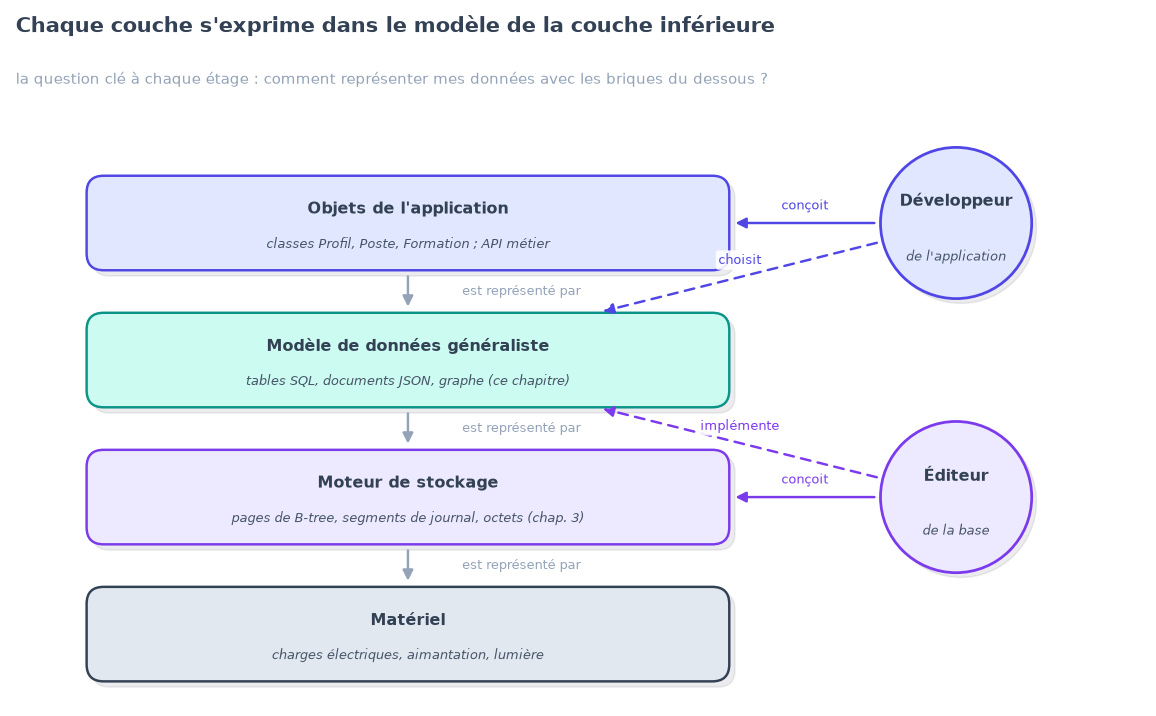

In [2]:
d = Diagram(12, 6.4, title="Chaque couche s'exprime dans le modèle de la couche inférieure",
            subtitle="la question clé à chaque étage : comment représenter mes données avec les briques du dessous ?")
layers = [
    ("app", "Objets de l'application", "classes Profil, Poste, Formation ; API métier", INDIGO),
    ("gen", "Modèle de données généraliste", "tables SQL, documents JSON, graphe (ce chapitre)", TEAL),
    ("eng", "Moteur de stockage", "pages de B-tree, segments de journal, octets (chap. 3)", VIOLET),
    ("hw", "Matériel", "charges électriques, aimantation, lumière", SLATE),
]
for i, (name, txt, sub, col) in enumerate(layers):
    d.box(name, 4.2, 5.1 - 1.45 * i, txt, sub=sub, color=col, w=6.8, h=1.0)
for (a, *_), (b, *_) in zip(layers, layers[1:]):
    d.arrow(a, b, "est représenté par", color=GRAY, label_offset=(1.2, 0))
d.box("dev", 10.0, 5.1, "Développeur", sub="de l'application", kind="user", w=1.6, color=INDIGO)
d.box("ven", 10.0, 2.2, "Éditeur", sub="de la base", kind="user", w=1.6, color=VIOLET)
d.arrow("dev", "app", "conçoit", color=INDIGO)
d.arrow("dev", "gen", "choisit", color=INDIGO, style="dashed")
d.arrow("ven", "gen", "implémente", color=VIOLET, style="dashed")
d.arrow("ven", "eng", "conçoit", color=VIOLET)
d.show()

Le choix du modèle généraliste (couche 2) est le plus lourd de conséquences pour le
développeur : certaines données et certaines requêtes s'expriment naturellement dans un
modèle et maladroitement dans un autre. Le chapitre compare donc les modèles
relationnel, document et graphe, ainsi
que leurs langages de requête.

> **À retenir.** Une application empile des modèles de données ; chacun masque la
> complexité de la couche inférieure. Le modèle généraliste choisi (tables, documents,
> graphe) détermine ce qui sera simple ou difficile à exprimer.